# 09 — Final Prediction, Full Test Evaluation & Model Comparison

## Project: Phishing URL Detection Using Machine Learning

### Objective

This notebook performs the **final evaluation and prediction stage** using the three tuned models:

- Logistic Regression
- Decision Tree
- Random Forest

The notebook evaluates the models on the **complete held-out test set**, not only 10 sample records.

### Evaluation protocol

- Complete dataset: 235,795 records
- Training set: approximately 80%
- Test set: approximately 20%
- Test evaluation is performed on **all test records**
- The 10-record prediction is retained only as a small demonstration at the end.

### Metrics reported

For every model:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- Specificity
- Balanced Accuracy
- MCC
- Confusion Matrix
- Full Classification Report

**Class mapping**

- `0 → Phishing`
- `1 → Legitimate`


In [2]:
# Cell 2 — Import libraries

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    matthews_corrcoef
)

print("NOTEBOOK 09 — FINAL EVALUATION ENVIRONMENT")
print("=" * 70)
print("Libraries imported successfully.")


NOTEBOOK 09 — FINAL EVALUATION ENVIRONMENT
Libraries imported successfully.


In [3]:
# Cell 3 — Load the selected-feature dataset

dataset_path = "../dataset/PhiUSIIL_Selected_Features.csv"

df = pd.read_csv(dataset_path)

print("DATASET LOADED")
print("=" * 70)
print("Dataset shape:", df.shape)
print("Total records:", len(df))
print("Number of selected features:", df.shape[1] - 1)
print("Target column:", "label")

X = df.drop(columns=["label"])
y = df["label"]

print("\nClass distribution:")
print(y.value_counts().sort_index())

print("\nClass mapping:")
print("0 → Phishing")
print("1 → Legitimate")


DATASET LOADED
Dataset shape: (235795, 41)
Total records: 235795
Number of selected features: 40
Target column: label

Class distribution:
label
0    100945
1    134850
Name: count, dtype: int64

Class mapping:
0 → Phishing
1 → Legitimate


In [4]:
# Cell 4 — Recreate the exact 80/20 URL-group split used in Notebooks 07 and 08

print("CREATING LEAKAGE-FREE URL-GROUP TRAIN/TEST SPLIT")
print("=" * 70)

url_data = pd.read_csv(
    "../dataset/PhiUSIIL_Engineered_Features.csv",
    usecols=["URL", "label"]
)

# One row per unique URL
url_groups = url_data.drop_duplicates(subset="URL")

# Same split settings used in Notebooks 07 and 08
train_url_groups, test_url_groups = train_test_split(
    url_groups,
    test_size=0.20,
    random_state=42,
    stratify=url_groups["label"]
)

train_url_set = set(train_url_groups["URL"])
test_url_set = set(test_url_groups["URL"])

train_mask = url_data["URL"].isin(train_url_set)
test_mask = url_data["URL"].isin(test_url_set)

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()
y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

common_urls = train_url_set.intersection(test_url_set)

print("Total records:", len(df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining percentage:",
      round(len(X_train) / len(df) * 100, 2), "%")
print("Testing percentage:",
      round(len(X_test) / len(df) * 100, 2), "%")

print("\nTraining features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])
print("URLs appearing in both sets:", len(common_urls))

assert len(common_urls) == 0, "URL leakage detected!"
assert len(X_train) + len(X_test) == len(df), "Train/test sizes do not add up!"

print("\n✅ 80/20 URL-group split recreated successfully.")
print("✅ No URL overlap between training and testing sets.")


CREATING LEAKAGE-FREE URL-GROUP TRAIN/TEST SPLIT
Total records: 235795
Training records: 188644
Testing records: 47151

Training percentage: 80.0 %
Testing percentage: 20.0 %

Training features: 40
Testing features: 40
URLs appearing in both sets: 0

✅ 80/20 URL-group split recreated successfully.
✅ No URL overlap between training and testing sets.


In [5]:
# Cell 5 — Load tuned models and scaler

model_paths = {
    "Logistic Regression": "../models/logistic_regression_tuned.pkl",
    "Decision Tree": "../models/decision_tree_tuned.pkl",
    "Random Forest": "../models/random_forest_tuned.pkl"
}

models = {}

print("LOADING TUNED MODELS")
print("=" * 70)

for model_name, model_path in model_paths.items():
    if not os.path.exists(model_path):
        raise FileNotFoundError(
            f"Required model file not found: {model_path}"
        )

    models[model_name] = joblib.load(model_path)
    print(f"✓ {model_name}: {type(models[model_name]).__name__}")

scaler_path = "../models/tuning_feature_scaler.pkl"

if not os.path.exists(scaler_path):
    raise FileNotFoundError(f"Scaler not found: {scaler_path}")

scaler = joblib.load(scaler_path)

print(f"✓ Scaler: {type(scaler).__name__}")

print("\n✅ All required models and scaler loaded.")


LOADING TUNED MODELS
✓ Logistic Regression: LogisticRegression
✓ Decision Tree: DecisionTreeClassifier
✓ Random Forest: RandomForestClassifier
✓ Scaler: StandardScaler

✅ All required models and scaler loaded.


In [6]:
# Cell 6 — Prepare test data exactly as required by each model

# Logistic Regression and Decision Tree were evaluated with the saved scaler.
# Random Forest uses the original selected numerical features.

X_test_scaled_array = scaler.transform(X_test)

# Keep feature names to avoid sklearn feature-name warnings.
X_test_scaled = pd.DataFrame(
    X_test_scaled_array,
    columns=X_test.columns,
    index=X_test.index
)

print("TEST DATA PREPARED")
print("=" * 70)
print("Original test data:", X_test.shape)
print("Scaled test data:", X_test_scaled.shape)

print("\nScaled test data mean:",
      round(X_test_scaled.mean().mean(), 6))
print("Scaled test data standard deviation:",
      round(X_test_scaled.std().mean(), 6))

print("\n✅ Test data prepared.")


TEST DATA PREPARED
Original test data: (47151, 40)
Scaled test data: (47151, 40)

Scaled test data mean: -0.000689
Scaled test data standard deviation: 0.957053

✅ Test data prepared.


In [7]:
# Cell 7 — Generate predictions on the COMPLETE test set

predictions = {}
probabilities = {}

print("GENERATING FULL TEST-SET PREDICTIONS")
print("=" * 70)

for model_name, model in models.items():

    if model_name in ["Logistic Regression", "Decision Tree"]:
        X_input = X_test_scaled
    else:
        # Random Forest model saved in Notebook 08 was trained on unscaled features.
        X_input = X_test

    y_pred = model.predict(X_input)
    y_prob = model.predict_proba(X_input)[:, 1]

    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    print(
        f"✓ {model_name}: "
        f"{len(y_pred):,} test predictions generated"
    )

print("\nNumber of test records evaluated:", len(y_test))
print("Number of models evaluated:", len(models))

print("\n✅ FULL TEST-SET PREDICTIONS COMPLETED.")


GENERATING FULL TEST-SET PREDICTIONS
✓ Logistic Regression: 47,151 test predictions generated
✓ Decision Tree: 47,151 test predictions generated
✓ Random Forest: 47,151 test predictions generated

Number of test records evaluated: 47151
Number of models evaluated: 3

✅ FULL TEST-SET PREDICTIONS COMPLETED.


In [8]:
# Cell 8 — Calculate complete evaluation metrics for every model

evaluation_results = []

for model_name in models:

    y_pred = predictions[model_name]
    y_prob = probabilities[model_name]

    # Confusion matrix:
    # [[TN, FP],
    #  [FN, TP]]
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    evaluation_results.append({
        "Model": model_name,
        "Test Samples": len(y_test),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Specificity": specificity,
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("COMPLETE TEST-SET MODEL EVALUATION")
print("=" * 70)

display(
    evaluation_df[
        [
            "Model",
            "Test Samples",
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score",
            "ROC-AUC",
            "Specificity",
            "Balanced Accuracy",
            "MCC"
        ]
    ].round(4)
)

print("\n✅ Accuracy, Precision, Recall, F1, ROC-AUC and additional metrics calculated.")


COMPLETE TEST-SET MODEL EVALUATION


,Model,Test Samples,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Specificity,Balanced Accuracy,MCC
0,Logistic Regression,47151,1.0,0.9999,1.0,1.0,1.0,0.9999,1.0,0.9999
1,Decision Tree,47151,1.0,1.0000,1.0,1.0,1.0,1.0000,1.0,1.0000
2,Random Forest,47151,1.0,1.0000,1.0,1.0,1.0,1.0000,1.0,1.0000



✅ Accuracy, Precision, Recall, F1, ROC-AUC and additional metrics calculated.


In [9]:
# Cell 9 — Detailed classification report for every model

print("DETAILED CLASSIFICATION REPORTS")
print("=" * 70)

for model_name in models:

    print("\n" + "=" * 70)
    print(model_name.upper())
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions[model_name],
            target_names=["Phishing", "Legitimate"],
            digits=4,
            zero_division=0
        )
    )

print("\nClass interpretation:")
print("0 → Phishing")
print("1 → Legitimate")


DETAILED CLASSIFICATION REPORTS

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    Phishing     1.0000    0.9999    1.0000     20181
  Legitimate     0.9999    1.0000    1.0000     26970

    accuracy                         1.0000     47151
   macro avg     1.0000    1.0000    1.0000     47151
weighted avg     1.0000    1.0000    1.0000     47151


DECISION TREE
              precision    recall  f1-score   support

    Phishing     1.0000    1.0000    1.0000     20181
  Legitimate     1.0000    1.0000    1.0000     26970

    accuracy                         1.0000     47151
   macro avg     1.0000    1.0000    1.0000     47151
weighted avg     1.0000    1.0000    1.0000     47151


RANDOM FOREST
              precision    recall  f1-score   support

    Phishing     1.0000    1.0000    1.0000     20181
  Legitimate     1.0000    1.0000    1.0000     26970

    accuracy                         1.0000     47151
   macro avg     1.0000    1.0000    1.0000  


Logistic Regression — CONFUSION MATRIX
Rows = Actual | Columns = Predicted
          Predicted
          Phishing  Legitimate
Phishing      20,179           2
Legitimate         0      26,970


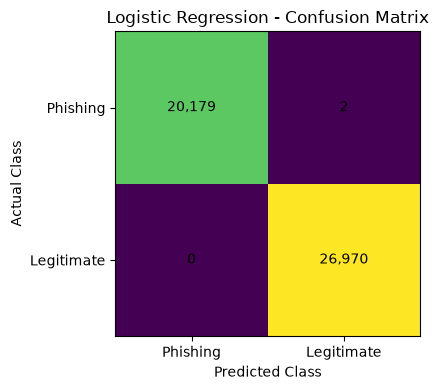


Decision Tree — CONFUSION MATRIX
Rows = Actual | Columns = Predicted
          Predicted
          Phishing  Legitimate
Phishing      20,180           1
Legitimate         0      26,970


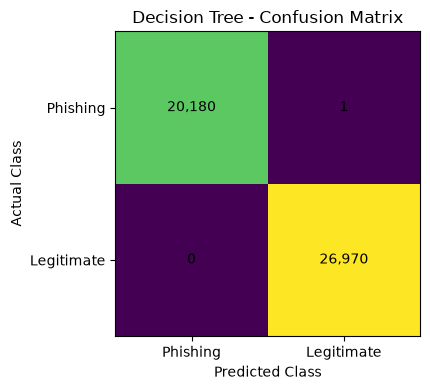


Random Forest — CONFUSION MATRIX
Rows = Actual | Columns = Predicted
          Predicted
          Phishing  Legitimate
Phishing      20,180           1
Legitimate         0      26,970


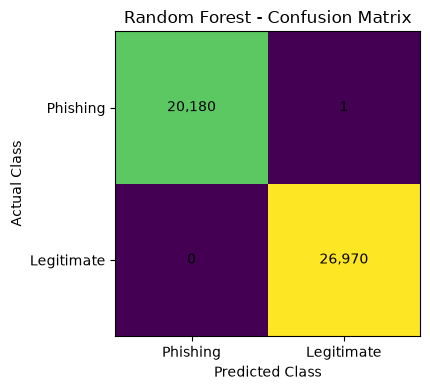

In [10]:
# Cell 10 — Confusion matrices for all models

for model_name in models:

    cm = confusion_matrix(
        y_test,
        predictions[model_name],
        labels=[0, 1]
    )

    print("\n" + "=" * 70)
    print(f"{model_name} — CONFUSION MATRIX")
    print("=" * 70)
    print("Rows = Actual | Columns = Predicted")
    print("          Predicted")
    print("          Phishing  Legitimate")
    print(f"Phishing   {cm[0,0]:9,d}  {cm[0,1]:10,d}")
    print(f"Legitimate {cm[1,0]:9,d}  {cm[1,1]:10,d}")

    plt.figure(figsize=(5, 4))
    plt.imshow(cm)
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.xticks([0, 1], ["Phishing", "Legitimate"])
    plt.yticks([0, 1], ["Phishing", "Legitimate"])

    for i in range(2):
        for j in range(2):
            plt.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")

    plt.tight_layout()
    plt.show()


In [11]:
# Cell 11 — Save complete evaluation results

os.makedirs("../results", exist_ok=True)

evaluation_path = "../results/final_test_evaluation_results.csv"

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

print("FINAL EVALUATION FILE SAVED")
print("=" * 70)
print(evaluation_path)

print("\nModels evaluated:", len(evaluation_df))
print("Test records per model:", len(y_test))

print("\n✅ Full evaluation results saved successfully.")


FINAL EVALUATION FILE SAVED
../results/final_test_evaluation_results.csv

Models evaluated: 3
Test records per model: 47151

✅ Full evaluation results saved successfully.


In [12]:
# Cell 12 — Determine the final model using available tuning/CV results

# IMPORTANT:
# The held-out test set is used for FINAL REPORTING, not for fitting.
# Where available, use cross-validation/tuning results for model selection.

final_model_name = None

cv_results_path = "../results/tuned_model_results.csv"

if os.path.exists(cv_results_path):

    cv_df = pd.read_csv(cv_results_path)

    print("CROSS-VALIDATION / TUNING RESULTS FOUND")
    print("=" * 70)
    display(cv_df)

    # Find a usable F1 column
    possible_f1_columns = [
        "Best CV F1-Score",
        "CV F1-Score",
        "F1-Score",
        "Best F1-Score"
    ]

    f1_column = next(
        (col for col in possible_f1_columns if col in cv_df.columns),
        None
    )

    if f1_column is not None and "Model" in cv_df.columns:

        best_row = cv_df.loc[
            cv_df[f1_column].idxmax()
        ]

        candidate = best_row["Model"]

        if candidate in models:
            final_model_name = candidate

            print("\nFinal model selected using tuning/CV F1-score:")
            print(final_model_name)
        else:
            print("\nThe tuning file contains a model name that is not loaded.")
            print("Final model will be selected from Notebook 08 evaluation results.")

if final_model_name is None:

    evaluation_file = "../results/evaluation_results.csv"

    if os.path.exists(evaluation_file):

        previous_evaluation = pd.read_csv(evaluation_file)

        print("\nNotebook 08 evaluation results found.")
        display(previous_evaluation.round(4))

        if "Model" in previous_evaluation.columns and "F1-Score" in previous_evaluation.columns:

            candidate = previous_evaluation.loc[
                previous_evaluation["F1-Score"].idxmax(),
                "Model"
            ]

            if candidate in models:
                final_model_name = candidate

    if final_model_name is None:
        # Safe fallback: use the first loaded model rather than silently
        # inventing a selection criterion.
        final_model_name = list(models.keys())[0]
        print("\nNo usable previous selection file was found.")
        print("Fallback model:", final_model_name)

final_model = models[final_model_name]

print("\n" + "=" * 70)
print("FINAL MODEL")
print("=" * 70)
print("Selected model:", final_model_name)
print("Model type:", type(final_model).__name__)


CROSS-VALIDATION / TUNING RESULTS FOUND


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.999958,0.999926,1.0,0.999963,1.000000
1,Decision Tree,0.999979,0.999963,1.0,0.999981,0.999975



Final model selected using tuning/CV F1-score:
Decision Tree

FINAL MODEL
Selected model: Decision Tree
Model type: DecisionTreeClassifier


In [13]:
# Cell 13 — Final model full-test performance

final_test_predictions = predictions[final_model_name]
final_test_probabilities = probabilities[final_model_name]

final_cm = confusion_matrix(
    y_test,
    final_test_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = final_cm.ravel()

final_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

print("FINAL MODEL — COMPLETE TEST-SET PERFORMANCE")
print("=" * 70)
print("Model:", final_model_name)
print("Test records:", len(y_test))

print(f"\nAccuracy:          {accuracy_score(y_test, final_test_predictions):.4f}")
print(f"Precision:         {precision_score(y_test, final_test_predictions, zero_division=0):.4f}")
print(f"Recall:            {recall_score(y_test, final_test_predictions, zero_division=0):.4f}")
print(f"F1-Score:          {f1_score(y_test, final_test_predictions, zero_division=0):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_test, final_test_probabilities):.4f}")
print(f"Specificity:       {final_specificity:.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, final_test_predictions):.4f}")
print(f"MCC:               {matthews_corrcoef(y_test, final_test_predictions):.4f}")

print("\nConfusion Matrix:")
print(final_cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_test_predictions,
        target_names=["Phishing", "Legitimate"],
        digits=4,
        zero_division=0
    )
)


FINAL MODEL — COMPLETE TEST-SET PERFORMANCE
Model: Decision Tree
Test records: 47151

Accuracy:          1.0000
Precision:         1.0000
Recall:            1.0000
F1-Score:          1.0000
ROC-AUC:           1.0000
Specificity:       1.0000
Balanced Accuracy: 1.0000
MCC:               1.0000

Confusion Matrix:
[[20180     1]
 [    0 26970]]

Classification Report:
              precision    recall  f1-score   support

    Phishing     1.0000    1.0000    1.0000     20181
  Legitimate     1.0000    1.0000    1.0000     26970

    accuracy                         1.0000     47151
   macro avg     1.0000    1.0000    1.0000     47151
weighted avg     1.0000    1.0000    1.0000     47151



In [14]:
# Cell 14 — Save full test-set predictions

full_prediction_results = pd.DataFrame({
    "Original_Index": X_test.index,
    "Actual_Class": y_test.to_numpy(),
    "Actual_Class_Name": y_test.map({
        0: "Phishing",
        1: "Legitimate"
    }).to_numpy(),
})

for model_name in models:
    full_prediction_results[f"{model_name}_Prediction"] = predictions[model_name]
    full_prediction_results[f"{model_name}_Prediction_Name"] = pd.Series(
        predictions[model_name],
        index=X_test.index
    ).map({
        0: "Phishing",
        1: "Legitimate"
    }).to_numpy()
    full_prediction_results[f"{model_name}_Probability_Legitimate"] = probabilities[model_name]

predictions_path = "../results/full_test_predictions.csv"

full_prediction_results.to_csv(
    predictions_path,
    index=False
)

print("FULL TEST PREDICTIONS SAVED")
print("=" * 70)
print(predictions_path)
print("Rows saved:", len(full_prediction_results))
print("Columns saved:", len(full_prediction_results.columns))

print("\n✅ Every test record has been predicted by all three models.")


FULL TEST PREDICTIONS SAVED
../results/full_test_predictions.csv
Rows saved: 47151
Columns saved: 12

✅ Every test record has been predicted by all three models.


In [15]:
# Cell 15 — 10-record prediction demonstration

# The 10 records are ONLY a demonstration.
# They are NOT used as the official accuracy/F1 evaluation.

demo_size = min(10, len(X_test))

demo_indices = X_test.sample(
    n=demo_size,
    random_state=100
).index

X_demo = X_test.loc[demo_indices]
y_demo = y_test.loc[demo_indices]

if final_model_name in ["Logistic Regression", "Decision Tree"]:
    X_demo_input = pd.DataFrame(
        scaler.transform(X_demo),
        columns=X_demo.columns,
        index=X_demo.index
    )
else:
    X_demo_input = X_demo

demo_predictions = final_model.predict(X_demo_input)
demo_probabilities = final_model.predict_proba(X_demo_input)

demo_results = pd.DataFrame({
    "Record": range(1, demo_size + 1),
    "Actual Class": y_demo.map({
        0: "Phishing",
        1: "Legitimate"
    }).to_numpy(),
    "Predicted Class": pd.Series(
        demo_predictions,
        index=demo_indices
    ).map({
        0: "Phishing",
        1: "Legitimate"
    }).to_numpy(),
    "Confidence": np.max(demo_probabilities, axis=1)
})

print("10-RECORD PREDICTION DEMONSTRATION")
print("=" * 70)
print("Final model:", final_model_name)
print("Demonstration records:", demo_size)

display(demo_results.round(4))

demo_correct = (
    y_demo.to_numpy() == demo_predictions
).sum()

print("\nDemonstration results:")
print("Correct:", demo_correct)
print("Incorrect:", demo_size - demo_correct)
print(f"Demonstration accuracy: {demo_correct / demo_size:.4f}")

print("\nNOTE:")
print("The official project metrics are the metrics calculated")
print(f"above on the COMPLETE test set of {len(y_test):,} records.")


10-RECORD PREDICTION DEMONSTRATION
Final model: Decision Tree
Demonstration records: 10


,Record,Actual Class,Predicted Class,Confidence
0,1,Legitimate,Legitimate,1.0
1,2,Legitimate,Legitimate,1.0
2,3,Phishing,Phishing,1.0
3,4,Legitimate,Legitimate,1.0
4,5,Phishing,Phishing,1.0
5,6,Phishing,Phishing,1.0
6,7,Legitimate,Legitimate,1.0
7,8,Phishing,Phishing,1.0
8,9,Legitimate,Legitimate,1.0
9,10,Phishing,Phishing,1.0



Demonstration results:
Correct: 10
Incorrect: 0
Demonstration accuracy: 1.0000

NOTE:
The official project metrics are the metrics calculated
above on the COMPLETE test set of 47,151 records.


## Final Conclusion

This notebook evaluates **all three tuned machine-learning models on the complete held-out test set**.

The 10-record section is only a prediction demonstration. It must **not** be used as the project's reported model accuracy.

For the report, use the values from:

- `final_test_evaluation_results.csv`
- the classification reports
- the confusion matrices
- `full_test_predictions.csv`

The final reported test performance should refer to the complete held-out test set, not the 10-record demonstration.
